<p align="center">
  <span style="color:Navy; font-size:200%; font-weight:bold; vertical-align:middle;">
    Temas Selectos: Python para Ciencias de la Tierra
  </span>
  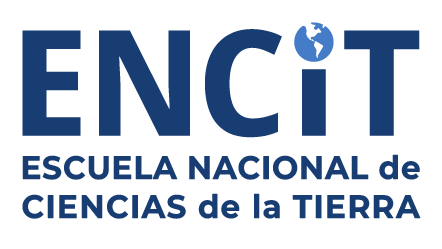
</p>
<p align="center" style="line-height:1.2;">
  <span style="color:RoyalBlue; font-size:160%;">Tema 4: Introducción al Aprendizaje Automático (Machine Learning) </span><br/>
  <span style="color:DodgerBlue; font-size:140%;"> Preprocesamiento de datos: Análisis univariado y bivariado  </span><br/>
  <span style="font-size:100%;color:forestgreen"> Escuela Nacional de Ciencias de la Tierra  |  Semestre 2026-I</span>
</p>

---


# **<font color="ForestGreen">  Análisis exploratorio de datos </font>**

El análisis exploratorio de datos (AED), o EDA por sus siglas en inglés, es una fase inicial en el análisis de datos que utiliza visualizaciones y estadísticas para investigar y comprender las características principales de un conjunto de datos, buscando patrones, valores atípicos y relaciones entre variables. Su objetivo es explorar la estructura de los datos, la calidad y la presencia de anomalías, no confirmar una hipótesis estadística preexistente. Es un proceso creativo y de descubrimiento que sirve como paso previo esencial antes de realizar un análisis estadístico o creación de modelos más complejos. 

## **<font color="SeaGreen"> Pronostico estacional de sequia </font>**

A lo largo de esta unidad estaremos construyendo modelos de machine learning para hacer un pronóstico estacional de sequía para un punto en el noroeste de México (lat = 29.725, lon = -109.725).


### Paso 0:   Plantear el problema

* ¿Cuál es el fenómeno físico que quiero estudiar?
    **El comportamiento de la sequía** 
* ¿Cuál es la variable dependiente?
   El SPI (Standardized Precipitation Index) —o Índice Estandarizado de Precipitación— es un indicador estadístico usado para medir las anomalías de precipitación (lluvia) en una región y período determinados. Su objetivo principal es cuantificar las condiciones de sequía o exceso de lluvia de manera estandarizada y comparable en el tiempo y el espacio.

    **La variable dependiente sera el SPI de 3 meses (que corresponde a una sequia meteorologica)**

* ¿Es una regresión o una clasificación? 



### Paso 1:  Datos 

* Obtener información diversa (¿Necesitamos muchos datos?).

    ¿Existen datos confiables que pueda usar?
    ¿Los datos tienen variedad?

* Remover información falsa, buscar/llenar valores faltantes… 

    Si no lleno los vacíos, el molodelo los aprenderá también.

* Proponer variables “predictoras” 

* Hacer un análisis estadístico de las variables propuestas.

* Definir las variables de entrada.


> Las variables que estan relacionadas con las sequías son aquellas que afectan al ciclo hidrológico y que pueden causar un estrés hídrico. Una alteración en estas variables detonan reacciones en cadena conocidas como procesos de retroalimentación.

Las variables que se proponen (inicialmente) para hacer los modelos, y sus procedencias, son las siguientes:


|Variable                                     | Abreviacion  | Base de datos  |
|---------------------------------------------|--------------|----------------|
|Precipitación acumulada                      | pcp          | CHIRPS         |
|Radiación de onda larga saliente             | OLR          | NCEP-NCAR      |
|SSTs en la región de El Niño 3.4             | SST          | NOAA           |
|Volumen de agua en la primera capa del suelo | swvl1        | ERA-5 Land     |
|Temperatura en la superficie del suelo       | skt          | ERA-5 Land     |
|Altura geopotencial en 600mb                  | hgt          | NCEP-NCAR      |





<div class="alert alert-block alert-info">
<b>Nota:</b> Por cuestiones de cómputo sólo obtendremos el pronostico del SPI de Marzo-Abril-Mayo (El trimestre más seco en México).  Vamos a crear el pronostico sin anticipación (usando predictores de DEF), con un mes de anticipación (usando predictores de NDE) y con 2 meses de anticipación (usando predictores de OND). 
</div>


<div class="alert alert-success">
    <b>Paso 1 : <b> La misión en esta clase es hacer el AED, vamos a hacer un análisis univariado (que ya saben hacer) y el análisis bivariado. Debemos corroborar que nuestros datos son buenos, es decir que no hay valores faltantes, presencia de valores atípicos extraños, etc...
</div>


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec

### **<font color="SeaGreen"> Vamos a explorar la base de datos </font>**

* Crea un DataFrame con los datos de `sequias_datos.csv` y muestra las primeras filas.
* Muestra cuáles son las columnas que existen en el DataFrame.
* Imprime la información del DataFrame para saber si hay valores faltantes. 

In [ ]:
df = ___________________________________
df.__________________________

In [2]:
# carga de archivo csv
df=pd.read_csv('sequias_datos.csv')
df.head()

,Year,sst_mean_SON,sst_mean_OND,sst_mean_NDE,sst_mean_DJF,sst_mean_Jan,spi,pcp_SON,pcp_OND,pcp_NDE,...,skt_SON,skt_OND,skt_NDE,skt_DJF,skt_Jan,swvl1_SON,swvl1_OND,swvl1_NDE,swvl1_DJF,swvl1_Jan
0,1981,26.295703,26.241972,26.281063,26.407555,26.583525,-0.672088,90.611435,34.211945,18.819138,...,294.19766,291.48044,289.14413,289.32132,288.82553,0.296509,0.238573,0.225010,0.206602,0.060151
1,1982,28.341490,28.636714,28.704208,28.716984,28.718637,0.551539,129.213300,89.716790,62.293777,...,293.33524,289.64480,286.61465,285.90000,284.20290,0.308189,0.322741,0.387607,0.378843,0.202828
2,1983,25.754122,25.448048,25.405423,25.782886,25.488600,0.256219,80.509700,31.199910,47.168045,...,292.82350,290.70163,287.93850,286.11597,284.93808,0.401436,0.244475,0.306793,0.449660,0.179581
3,1984,25.860297,25.449453,25.195422,25.309907,25.162136,0.141934,61.921604,38.681725,32.634262,...,292.55923,291.47500,288.13890,287.97880,284.60580,0.376130,0.234884,0.267290,0.293302,0.136410
4,1985,26.008695,26.037523,25.977030,25.871038,25.767262,-0.855751,51.623270,48.386490,31.393246,...,294.60364,291.35147,289.12784,288.39290,287.57596,0.251178,0.252185,0.201228,0.210402,0.060556


In [3]:
df.columns

Index(['Year', 'sst_mean_SON', 'sst_mean_OND', 'sst_mean_NDE', 'sst_mean_DJF',
       'sst_mean_Jan', 'spi', 'pcp_SON', 'pcp_OND', 'pcp_NDE', 'pcp_DJF',
       'pcp_Jan', 'hgt_SON', 'hgt_OND', 'hgt_NDE', 'hgt_DJF', 'hgt_Jan',
       'olr_SON', 'olr_OND', 'olr_NDE', 'olr_DJF', 'olr_Jan', 'skt_SON',
       'skt_OND', 'skt_NDE', 'skt_DJF', 'skt_Jan', 'swvl1_SON', 'swvl1_OND',
       'swvl1_NDE', 'swvl1_DJF', 'swvl1_Jan'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Year          43 non-null     int64  
 1   sst_mean_SON  43 non-null     float64
 2   sst_mean_OND  43 non-null     float64
 3   sst_mean_NDE  43 non-null     float64
 4   sst_mean_DJF  43 non-null     float64
 5   sst_mean_Jan  43 non-null     float64
 6   spi           43 non-null     float64
 7   pcp_SON       43 non-null     float64
 8   pcp_OND       43 non-null     float64
 9   pcp_NDE       43 non-null     float64
 10  pcp_DJF       43 non-null     float64
 11  pcp_Jan       43 non-null     float64
 12  hgt_SON       43 non-null     float64
 13  hgt_OND       43 non-null     float64
 14  hgt_NDE       43 non-null     float64
 15  hgt_DJF       43 non-null     float64
 16  hgt_Jan       43 non-null     float64
 17  olr_SON       43 non-null     float64
 18  olr_OND       43 non-null     fl

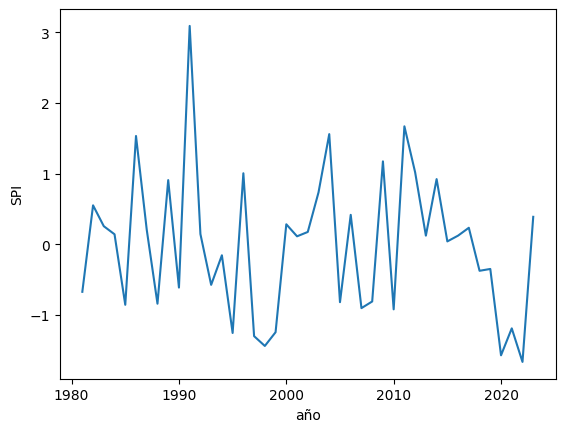

In [9]:
# Antes de empezar, van a graficar la linea de tiempo del SPI (Usando un lineplot)
plt.figure()
plt.plot(df.Year,df.spi)
plt.xlabel("año")
plt.ylabel("SPI")
plt.show()



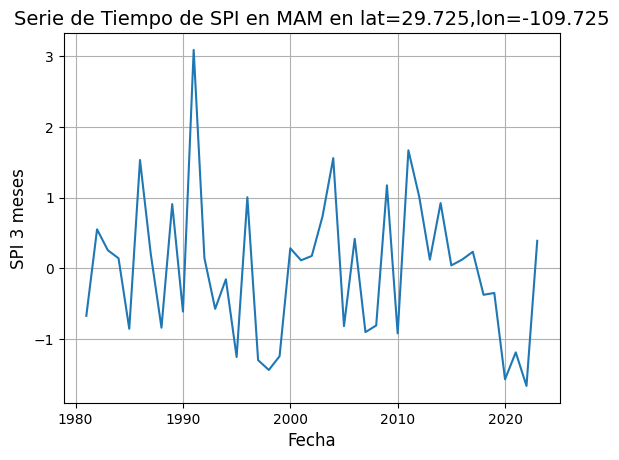

In [7]:
plt.figure()
sns.lineplot(x='Year',y='spi', data=df, markers='o')
# Añadir títulos y etiquetas
plt.title('Serie de Tiempo de SPI en MAM en lat=29.725,lon=-109.725', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('SPI 3 meses', fontsize=12)

# Mostrar el gráfico
plt.grid(True)
plt.show()

### **<font color="SeaGreen"> Análisis estadistico univarido </font>**

Primero, para hacer el pronóstico del SPI de Marzo-Abril-Mayo vamos a usar únicamente las variables de Diciembre-Enero-Febrero. Con esto crearemos un pronóstico sin anticipación. 

* Crea un nuevo DataFrame que sólo contenga las variables `'spi', 'sst_mean_DJF', 'pcp_DJF', 'hgt_DJF', 'olr_DJF', 'skt_DJF', 'swvl1_DJF'`
* Obten un resumen de las medidas de tendencia central, de posición, y dispersión de los datos.
* Obten los histogramas y los boxplots para cada variable.


In [12]:
VariablesNumAnalis = [ 'spi', 'sst_mean_DJF', 'pcp_DJF', 'hgt_DJF', 'olr_DJF', 'skt_DJF', 'swvl1_DJF']

df_DEF = df[VariablesNumAnalis]
df_DEF.head()

,spi,sst_mean_DJF,pcp_DJF,hgt_DJF,olr_DJF,skt_DJF,swvl1_DJF
0,-0.672088,26.407555,23.249588,4391.535,256.32935,289.32132,0.206602
1,0.551539,28.716984,56.149323,4352.721,248.58508,285.90000,0.378843
2,0.256219,25.782886,40.461422,4379.268,247.67094,286.11597,0.449660
3,0.141934,25.309907,39.615967,4389.627,245.90265,287.97880,0.293302
4,-0.855751,25.871038,35.157770,4390.934,255.53215,288.39290,0.210402


In [13]:
df_DEF.describe()

,spi,sst_mean_DJF,pcp_DJF,hgt_DJF,olr_DJF,skt_DJF,swvl1_DJF
count,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000
mean,-0.016937,26.541807,40.340806,4391.231047,248.316209,288.018711,0.283622
std,1.013312,1.087616,23.061275,15.446717,10.243508,1.256816,0.114965
min,-1.664030,24.708334,15.390759,4344.681000,221.466550,284.960050,0.170943
25%,-0.829494,25.774264,23.361033,4387.099650,241.378905,287.210225,0.210581
50%,0.122534,26.390895,37.050938,4394.726000,247.670940,288.246580,0.251518
75%,0.484214,27.223847,48.584763,4400.061750,255.930750,288.898575,0.313126
max,3.090000,29.016521,131.885560,4413.182000,267.431300,289.966200,0.744680


##### Para obtener un resumen estadístico más completo, podemos definir la siguiente función.

In [14]:
def estadigrafos(df, VariableName):
    """
    Calcula estadísticas descriptivas básicas para una columna específica de un DataFrame.

    Parámetros:
    - df (pandas.DataFrame): DataFrame que contiene los datos.
    - VariableName (str): Nombre de la columna para la cual calcular las estadísticas.

    Retorna:
    - pandas.DataFrame: DataFrame con las estadísticas de la columna especificada.
    """
    # Calcula las estadísticas deseadas
    minim = df[VariableName].min()
    Q1 = df[VariableName].quantile(0.25)
    prome = df[VariableName].mean()
    Q2 = df[VariableName].median()
    Q3 = df[VariableName].quantile(0.75)
    maxim = df[VariableName].max()
    varia = df[VariableName].var()
    desvi = df[VariableName].std()
    rango = maxim - minim
    IQR = Q3 - Q1
    coefv = desvi / prome if prome != 0 else np.nan  # Previene división por cero
    simetria = df[VariableName].skew()
    curtosis = df[VariableName].kurtosis()

    # Crea un DataFrame con los resultados
    estadisticas = pd.DataFrame({
        VariableName: [minim, Q1, prome, Q2, Q3, maxim, varia, desvi, rango, IQR, coefv, simetria, curtosis]
    }, index=['Mínimo', 'Primer Cuartil', 'Promedio', 'Mediana', 'Tercer Cuartil', 'Máximo', 'Varianza', 'Desviación Estandar', 'Rango', 'IQR', 'Coeficiente de variación', 'Simetria', 'Curtosis'])

    return estadisticas.round(2)

In [15]:
estadisticas = pd.DataFrame()
for variable in VariablesNumAnalis:
    df_est = estadigrafos(df_DEF, variable)
    estadisticas = pd.concat([estadisticas, df_est], axis = 1)

estadisticas

,spi,sst_mean_DJF,pcp_DJF,hgt_DJF,olr_DJF,skt_DJF,swvl1_DJF
Mínimo,-1.66,24.71,15.39,4344.68,221.47,284.96,0.17
Primer Cuartil,-0.83,25.77,23.36,4387.10,241.38,287.21,0.21
Promedio,-0.02,26.54,40.34,4391.23,248.32,288.02,0.28
Mediana,0.12,26.39,37.05,4394.73,247.67,288.25,0.25
Tercer Cuartil,0.48,27.22,48.58,4400.06,255.93,288.90,0.31
Máximo,3.09,29.02,131.89,4413.18,267.43,289.97,0.74
Varianza,1.03,1.18,531.82,238.60,104.93,1.58,0.01
Desviación Estandar,1.01,1.09,23.06,15.45,10.24,1.26,0.11
Rango,4.75,4.31,116.49,68.50,45.96,5.01,0.57
IQR,1.31,1.45,25.22,12.96,14.55,1.69,0.10


In [16]:
def HistBox(variables, df):
    plt.figure(figsize=(20, 20))
    outer_grid = gridspec.GridSpec(6, 2, wspace=0.2, hspace=0.4)
    custom_params = {"axes.spines.right": True, "axes.spines.top": True, "axes.spines.left": True}
    sns.set_theme(style='whitegrid', context="talk", rc=custom_params, color_codes = True)
    sns.set_style("ticks", {"axes.grid": True, "grid.linestyle": "--"})

    for i, variable in enumerate(variables):
        inner_grid = gridspec.GridSpecFromSubplotSpec(2, 1,
                                                      subplot_spec=outer_grid[i],
                                                      height_ratios=[4, 1],
                                                      hspace=0.02)  # Ajustado para minimizar el espacio entre histogramas y boxplots

        # Histograma
        ax_hist = plt.Subplot(plt.gcf(), inner_grid[0])
        sns.histplot(df[variable], kde=True, stat='density', color='yellowgreen', ax=ax_hist)
        ax_hist.set_title(variable)
        ax_hist.set_xlabel('')  # Mantener esto para limpieza
        plt.gcf().add_subplot(ax_hist)
        ax_hist.tick_params(axis='x',          # Cambios para ocultar solo los ticks (no las etiquetas, que ya están ocultas)
                            which='both',      # Afecta a ticks mayores y menores
                            bottom=False,      # Oculta ticks inferiores
                            top=False,         # Oculta ticks superiores (si estuvieran visibles)
                            labelbottom=False) # Oculta las etiquetas de los ticks inferiores
        # Calcula y anota estadísticas
        mean = df[variable].mean()
        median = df[variable].median()
        mode = df[variable].mode()[0]  # Moda
        max_value = df[variable].max()
        min_value = df[variable].min()

        # Agrega líneas verticales para cada estadística
        lines = [
            ax_hist.axvline(mean, color='red', linestyle='dashed', linewidth=2),
            ax_hist.axvline(median, color='green', linestyle='dashed', linewidth=2)#,
        ]

        ax_hist.grid(True)

        # Boxplot
        ax_box = plt.Subplot(plt.gcf(), inner_grid[1], sharex=ax_hist)
        sns.boxplot(x=df[variable], ax=ax_box, color='lightgreen', showmeans=True,
                    meanprops={"marker":"o", "markerfacecolor":'red',
                               "markeredgecolor":"gray", "markersize":"10"})
        ax_box.set_xlabel('')
        ax_box.tick_params(axis='x',          # Cambios para ocultar solo los ticks (no las etiquetas, que ya están ocultas)
                            which='both',      # Afecta a ticks mayores y menores
                            bottom=True,      # Oculta ticks inferiores
                            top=True,         # Oculta ticks superiores (si estuvieran visibles)
                            labelbottom=True)
        plt.gcf().add_subplot(ax_box)

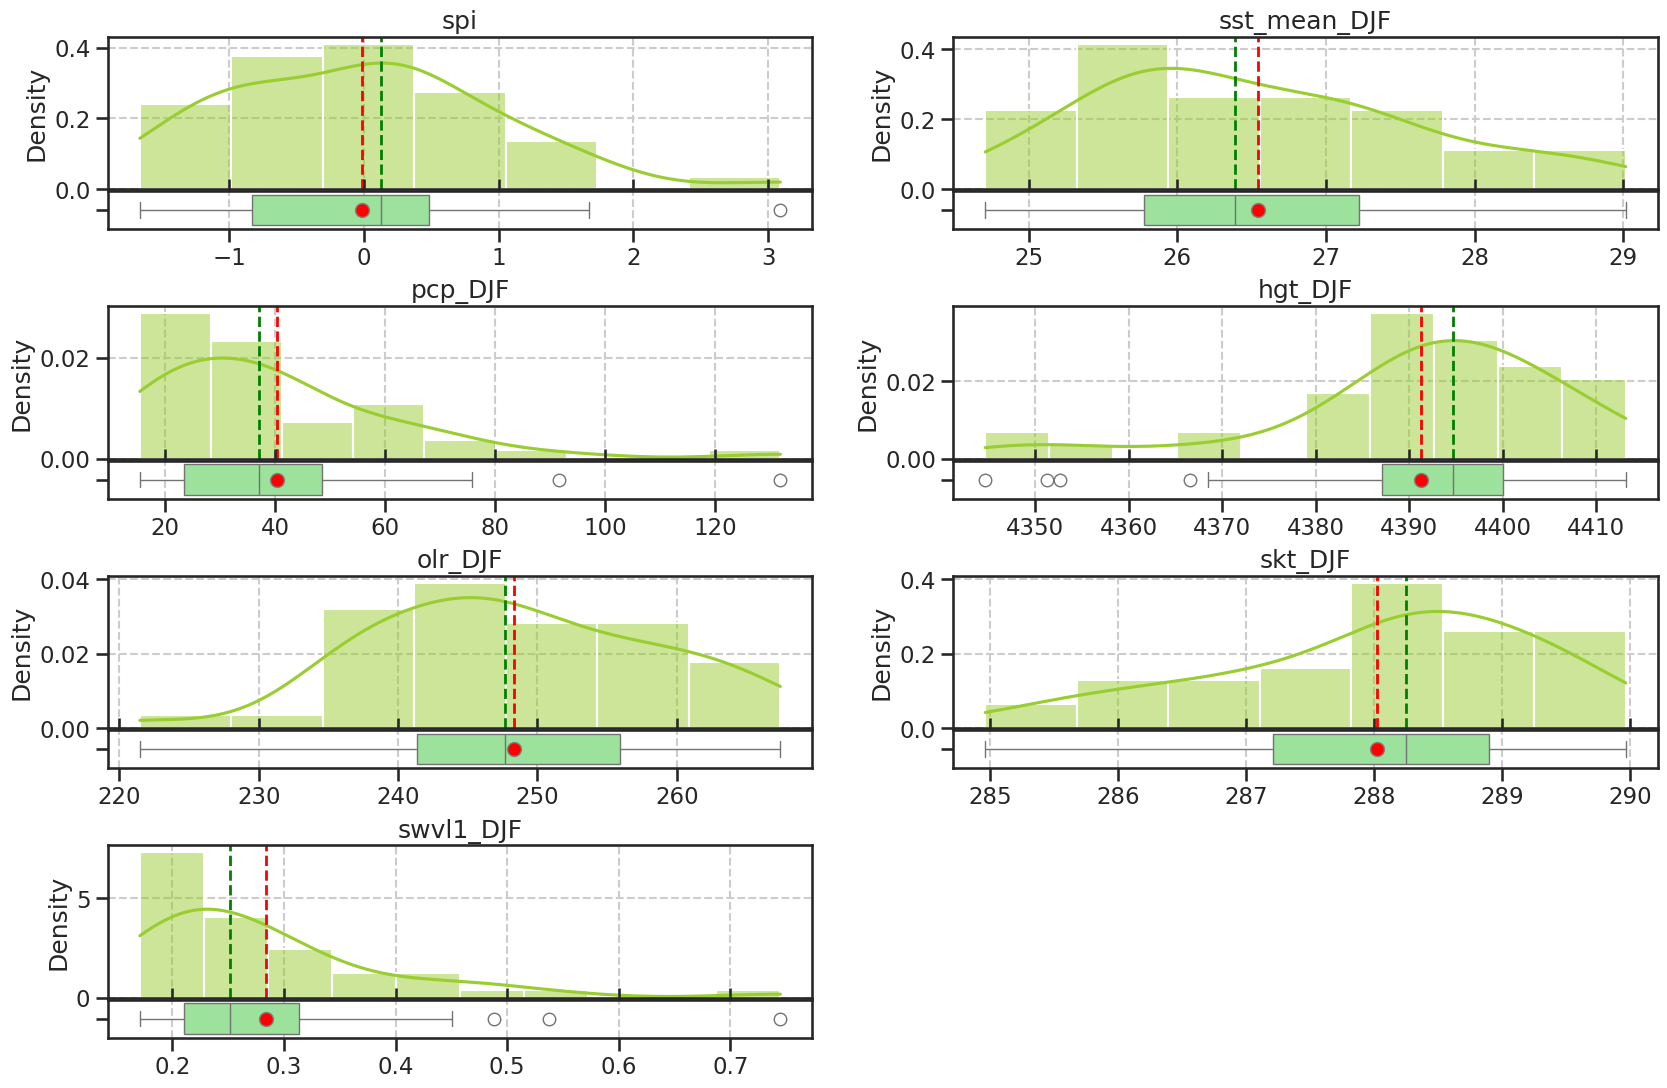

In [17]:
HistBox(VariablesNumAnalis, df_DEF)

In [ ]:
for i in VariablesNumAnalis:
    plt.boxplot(df_DEF[i])
    plt.title(i)
    plt.show()

### **<font color="blue"> Análisis bivariado </font>** 

El análisis bivariado en machine learning (aprendizaje automático) es fundamental para comprender la relación entre dos variables a la vez, lo cual es crucial para varios pasos del proceso de desarrollo del modelo.

Sus principales propósitos son:

* **Identificar relaciones y patrones:** Permite descubrir si existe una asociación, dependencia o correlación entre dos variables (por ejemplo, entre las horas de estudio y el rendimiento académico). Esto puede revelar tendencias y patrones que no son evidentes con el análisis univariado (de una sola variable).
* **Selección de características (Feature Selection):** Ayuda a determinar qué variables de entrada son más relevantes para predecir la variable objetivo. Si una variable de entrada no tiene una relación significativa con la variable objetivo, podría descartarse para simplificar el modelo y mejorar su eficiencia.
* **Ingeniería de características (Feature Engineering):** Al entender cómo se relacionan dos variables, se pueden crear nuevas características combinadas o transformadas que capturen mejor la información para el modelo. Esto puede resultar en modelos más flexibles y con mejor rendimiento.
* **Entender la dirección e intensidad de la relación:** Permite cuantificar la fuerza y el tipo de asociación. Por ejemplo, una correlación positiva indica que ambas variables aumentan juntas, mientras que una negativa muestra que una disminuye cuando la otra aumenta.
* **Informar el preprocesamiento de datos:** Los hallazgos del análisis bivariado pueden guiar decisiones sobre cómo manejar los datos, como la imputación de valores faltantes o la transformación de variables, asegurando que los datos sean adecuados para el análisis posterior.
* **Mejorar la interpretabilidad del modelo:** Comprender las relaciones subyacentes entre las características y la variable objetivo facilita la explicación de cómo el modelo llega a sus predicciones.

El análisis bivariado consiste en obtener correlaciones, y gráficos de dispersion (pairplots). 
Ahora, vamos a obtener estos dos recursos.

1. Obtener los mapas de calor con las correlaciones (Correlacion de pearson y correlacion de Spearman) de las variables.
2. Obtener los pairplots 

In [20]:
# Para obtener las matrices de correlacion:
pearson_correlation_matrix = df_DEF.corr(method='pearson')
# Obtengan la metriz de correlacion de Speaman. 
#spearman_correlation_matrix = ________________________________

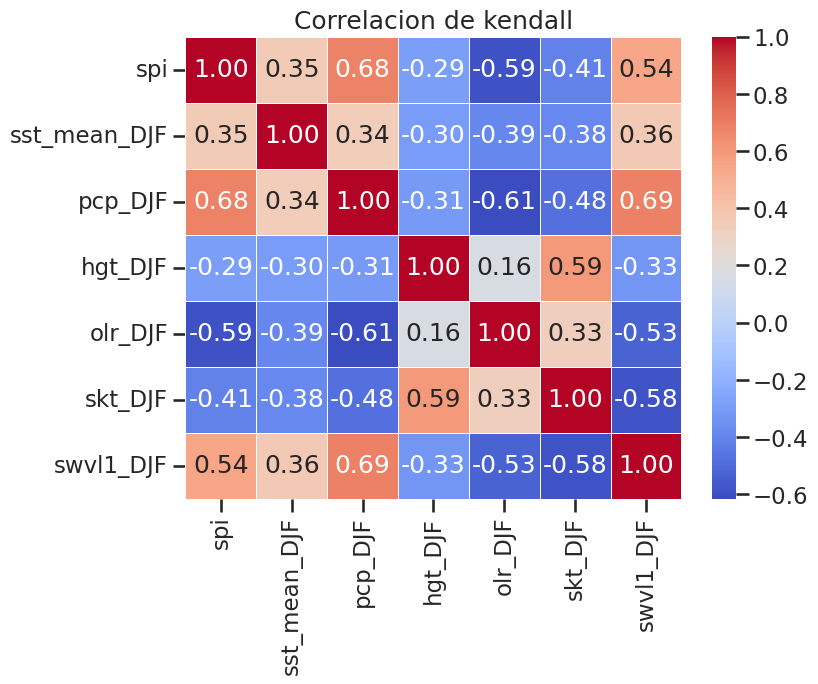

In [21]:
# Ahora vamos a creat el heatmap de la correlacion de pearson

plt.figure(figsize=(8, 6))
sns.heatmap(
    pearson_correlation_matrix,
    annot=True,      # Muestra los valores de correlacion en el heatmap 
    cmap='coolwarm', # Escogemos una paleta de colores (e.g., 'coolwarm', 'viridis', 'RdBu')
    fmt=".2f",       # Formato para que solo aparezcan dos decimales. 
    linewidths=.5    
)
plt.title('Correlacion de Pearson')
plt.show()         

In [ ]:
# A ustedes les toca obtener el heatmap de la correlacion de Spearman 


___________________________________________


In [22]:
# Para obtener las matrices de correlacion:

pearson_correlation_matrix = df_DEF.corr(method='pearson')
spearman_correlation_matrix = df_DEF.corr(method='spearman')

In [ ]:
# Ahora vamos a creat el heatmap de la correlacion de pearson

plt.figure(figsize=(8, 6))
sns.heatmap(
    pearson_correlation_matrix,
    annot=True,      # Muestra los valores de correlacion en el heatmap 
    cmap='coolwarm', # Escogemos una paleta de colores (e.g., 'coolwarm', 'viridis', 'RdBu')
    fmt=".2f",       # Formato para que solo aparezcan dos decimales. 
    linewidths=.5    
)
plt.title('Correlacion de Pearson')
plt.show()     

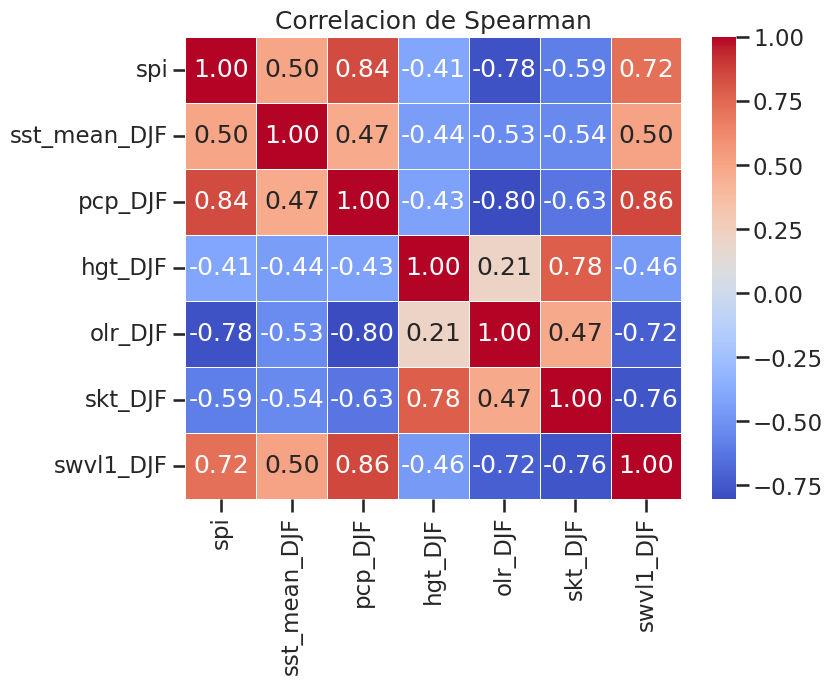

In [23]:
# Ahora vamos a creat el heatmap de la correlacion de pearson

plt.figure(figsize=(8, 6))
sns.heatmap(
    spearman_correlation_matrix,
    annot=True,      # Muestra los valores de correlacion en el heatmap 
    cmap='coolwarm', # Escogemos una paleta de colores (e.g., 'coolwarm', 'viridis', 'RdBu')
    fmt=".2f",       # Formato para que solo aparezcan dos decimales. 
    linewidths=.5    
)
plt.title('Correlacion de Spearman')
plt.show()     

<Figure size 640x480 with 0 Axes>

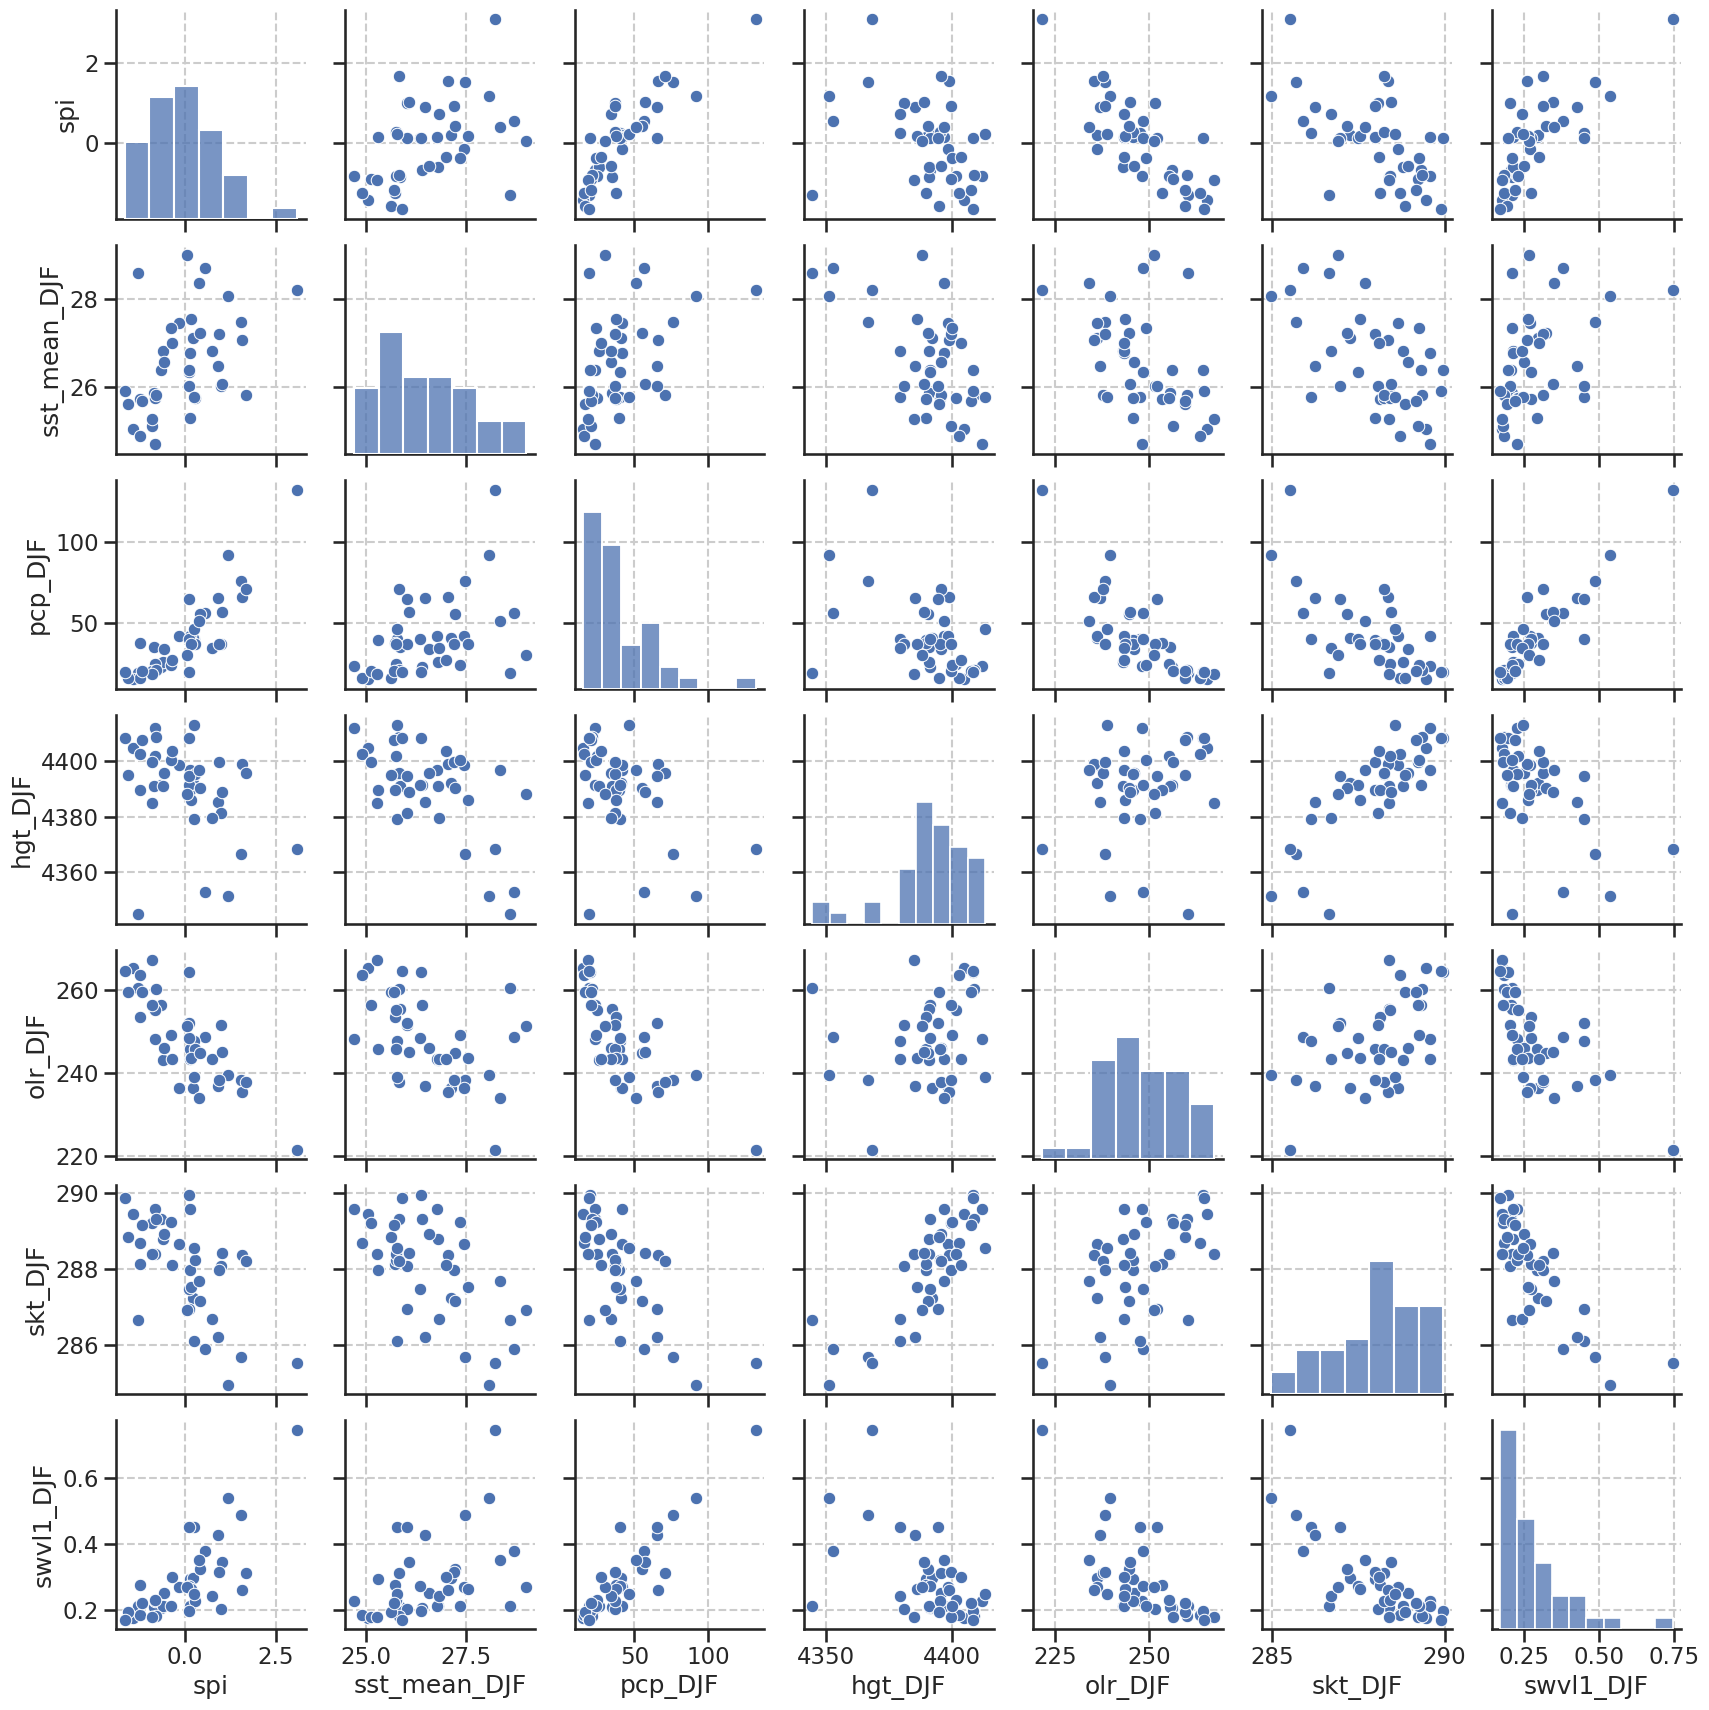

In [24]:
plt.figure()
sns.pairplot(df_DEF)
plt.show()

---
<a name='ej-1'></a>
### **<font color="DodgerBlue"> Ejercicio 1 </font>**

<font color="DarkBlue"> 1. Ahora es su turno, van hacer el AED considerando ahora los predictores de NDE y OND.

---

---
<a name='ej-1'></a>
### **<font color="DodgerBlue"> Ejercicio 2 </font>**

<font color="DarkBlue"> Elegir una base de datos para hacer su propio modelo.
1. Debe ser un problema de regresión (predecir valores contínuos).
2. Deden tener al menos 3 variables independientes (predictores).
3. La base de datos debe contener al menos 100 observaciones.

por ejem: predecir la temperatura de la siguiente hora con datos de dos horas antes.
predecir los niveles de contaminación (PM10) de la tarde a partir de datos de unas horas antes.
predecir la porosidad de rocas a partir de otras variables


---